# Notebook 14 — Offline Replay & Latency Benchmark (MVP First)

**Goal:** replay deterministic user requests and measure **P50/P95/P99**, QPS, candidate counts, score/rank parity, user coverage and audits for Retrieval → LightGBM → DeepFM → MMR.

**Two explicitly separate modes:**
1. **`cached_artifact_replay`**: in-memory lookup of Notebook 08/10/11/13 **precomputed** outputs. This is **not** model inference or online retrieval latency.
2. **`model_inference_replay`**: cached retrieval candidates + live LightGBM Booster.predict + live PyTorch DeepFM forward + greedy MMR. Feature rows are already available in memory and selected per request; this is **not** raw-event feature computation or online candidate generation. Report each stage separately, including selection/materialization overhead.

**Timing caveats:** single-process, sequential, local machine; no network, serialization, concurrency, cold-start, or real online serving. CUDA synchronization included. CPU and GPU timings must not be compared as equivalent production results. The baseline uses Notebook 13's λ selected on Validation; Test is not used to tune settings.

In [1]:
from pathlib import Path
import json,time,sys,platform,gc,math,random
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import duckdb,torch,lightgbm as lgb
from IPython.display import display
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
assert ROOT is not None,'Missing data/processed/notebook02.duckdb: open from project root or notebooks/'
OUT=ROOT/'data'/'processed'; REPORT=ROOT/'data'/'reports'; MODELS=ROOT/'models';PLOTS=REPORT/'notebook14_plots'
REPORT.mkdir(parents=True,exist_ok=True);PLOTS.mkdir(parents=True,exist_ok=True)
SPLIT='test' # fixed held-out replay set; no model/parameter selection on Test
N_REQUESTS=60;WARMUP_REQUESTS=5;MMR_POOL=150;MMR_DEPTH=100;TOP_K=20
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
REQUIRED=[OUT/f'{SPLIT}_fusion_rrf_top500.parquet',OUT/f'{SPLIT}_ranking_features_top500.parquet',OUT/f'{SPLIT}_lightgbm_binary_top500.parquet',OUT/f'{SPLIT}_deepfm_deepfm_top500.parquet',OUT/f'{SPLIT}_mmr_top500.parquet',MODELS/'notebook10_lightgbm_binary.txt',MODELS/'notebook11_deepfm_checkpoint.pt',REPORT/'notebook13_mmr_report.json']
missing=[str(p) for p in REQUIRED if not p.is_file()];assert not missing,'Missing upstream artifacts:\n'+'\n'.join(missing)
MMR_LAMBDA=float(json.loads((REPORT/'notebook13_mmr_report.json').read_text(encoding='utf-8'))['mmr']['selected_lambda'])
print('Root:',ROOT,'Device:',DEVICE,'MMR lambda (frozen):',MMR_LAMBDA,'Requests:',N_REQUESTS)


Root: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks Device: cuda MMR lambda (frozen): 0.9 Requests: 60


## 1. Read artifacts once (excluded from warm request latency)

The candidate universe is exactly the Notebook 08 Top-500. Merge using `(user_id,item_id)`, never row position. Enforce 500 distinct items/user and full cross-stage coverage. Preloading is **explicitly excluded** from warm timings; separately record artifact-load time.

In [2]:
t_load=time.perf_counter()
paths={'retrieval':OUT/f'{SPLIT}_fusion_rrf_top500.parquet','features':OUT/f'{SPLIT}_ranking_features_top500.parquet',
       'lgbm':OUT/f'{SPLIT}_lightgbm_binary_top500.parquet','deepfm':OUT/f'{SPLIT}_deepfm_deepfm_top500.parquet','mmr':OUT/f'{SPLIT}_mmr_top500.parquet'}
DATA={name:pd.read_parquet(path) for name,path in paths.items()}
for name,d in DATA.items():
    assert {'user_id','item_id'}<=set(d.columns),(name,d.columns.tolist())
    assert not d[['user_id','item_id']].duplicated().any(),f'Duplicate pairs: {name}'
    sz=d.groupby('user_id').size();assert len(sz)>0 and sz.min()==sz.max()==500,(name,sz.describe())
    print(name,len(d),'users',len(sz),'columns',d.columns.tolist()[:15])
keys=DATA['retrieval'][['user_id','item_id']]
for name,d in DATA.items():
    if name!='retrieval':
        assert len(keys.merge(d[['user_id','item_id']],on=['user_id','item_id'],validate='one_to_one'))==len(keys),f'Candidate mismatch: {name}'
# Index only sampled users to limit RAM (large feature Parquet ~1.8M rows).
USERS=np.array(sorted(DATA['retrieval'].user_id.unique()),dtype=np.int64)
_rng=np.random.default_rng(SEED)
selected=_rng.choice(USERS,size=min(N_REQUESTS,len(USERS)),replace=False).astype(np.int64)
SAMPLED=set(map(int,selected))
USER_DATA={name:{int(uid):sub.reset_index(drop=True) for uid,sub in d[d.user_id.isin(SAMPLED)].groupby('user_id',sort=False)} for name,d in DATA.items()}
assert all(set(USER_DATA[k])==SAMPLED for k in USER_DATA)
del DATA;gc.collect()
load_seconds=time.perf_counter()-t_load
print('Artifact load + index seconds:',round(load_seconds,3))


retrieval 1786000 users 3572 columns ['user_id', 'item_id', 'retrieval_rank', 'retrieval_score', 'source_count', 'from_popularity', 'from_cf', 'from_faiss', 'from_category', 'is_fallback', 'retrieval_source']
features 1786000 users 3572 columns ['user_id', 'item_id', 'cutoff_ts', 'label', 'retrieval_rank', 'rrf_score', 'source_count', 'from_popularity', 'from_cf', 'from_faiss', 'from_category', 'is_fallback', 'popularity_rank', 'popularity_score', 'cf_rank']
lgbm 1786000 users 3572 columns ['user_id', 'item_id', 'label', 'score', 'original_rank', 'model_rank']
deepfm 1786000 users 3572 columns ['user_id', 'item_id', 'label', 'score', 'original_rank', 'model_rank']
mmr 1786000 users 3572 columns ['user_id', 'item_id', 'label', 'deepfm_score', 'deepfm_rank', 'category_id', 'parent_category_id', 'root_category_id', 'mmr_rank', 'mmr_lambda']
Artifact load + index seconds: 5.854


## 2. Frozen model reconstruction (real inference path)

LightGBM categorical feature levels are stored in the model's `pandas_categorical` metadata; DeepFM uses Notebook 11 checkpoint vocabularies, train-fitted numerical transforms and exact architecture. Do not refit preprocessing on Test.

In [3]:
booster=lgb.Booster(model_file=str(MODELS/'notebook10_lightgbm_binary.txt'))
# Trusted locally produced checkpoint. PyTorch 2.6+ defaults weights_only=True; this checkpoint holds tensors + primitive containers.
checkpoint_path=MODELS/'notebook11_deepfm_checkpoint.pt'
try: ckpt=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
except Exception as e: raise RuntimeError('Cannot load trusted Notebook 11 checkpoint with weights_only=True; inspect checkpoint and PyTorch version') from e
NUMS=list(ckpt['num_features']);CATS=list(ckpt['categorical_features']);CATCOLS=['category_id','parent_category_id','root_category_id']
class DeepFM(torch.nn.Module):
    def __init__(self,n_num,cards,dim=8,hidden=64,dropout=.35):
        super().__init__();self.dim=dim;self.n_num=n_num
        self.num_linear=torch.nn.Parameter(torch.zeros(n_num));self.num_fm=torch.nn.Parameter(torch.randn(n_num,dim)*.01)
        self.cat_linear=torch.nn.ModuleList([torch.nn.Embedding(c,1,padding_idx=0) for c in cards]);self.cat_fm=torch.nn.ModuleList([torch.nn.Embedding(c,dim,padding_idx=0) for c in cards])
        self.bias=torch.nn.Parameter(torch.zeros(()))
        self.deep=torch.nn.Sequential(torch.nn.Linear(n_num+len(cards)*dim,hidden),torch.nn.ReLU(),torch.nn.Dropout(dropout),torch.nn.Linear(hidden,hidden//2),torch.nn.ReLU(),torch.nn.Dropout(dropout),torch.nn.Linear(hidden//2,1))
    def forward(self,x,cat):
        linear=(x*self.num_linear).sum(1)+self.bias;embeddings=[x.unsqueeze(-1)*self.num_fm.unsqueeze(0)];deep_c=[]
        for j,(e1,e2) in enumerate(zip(self.cat_linear,self.cat_fm)):
            linear=linear+e1(cat[:,j]).squeeze(-1);z=e2(cat[:,j]);embeddings.append(z.unsqueeze(1));deep_c.append(z)
        z=torch.cat(embeddings,dim=1);fm=.5*((z.sum(dim=1)**2-z.square().sum(dim=1)).sum(dim=1))
        return linear+fm+self.deep(torch.cat([x]+deep_c,dim=1)).squeeze(-1)
model=DeepFM(len(NUMS),list(ckpt['category_cardinalities']),int(ckpt['embedding_dim']),int(ckpt['hidden_dim']),float(ckpt['dropout']))
model.load_state_dict(ckpt['state_dict'],strict=True);model=model.to(DEVICE).eval()
# LightGBM model may contain categorical levels learned across train/validation/test in Notebook 10; reuse saved metadata exactly.
LGBM_FEATURES=list(booster.feature_name());LGBM_CATS=[c for c in LGBM_FEATURES if c in CATS]
assert len(LGBM_FEATURES)==len(NUMS)+len(CATS), 'Feature count mismatch'
assert len(booster.pandas_categorical or [])==len(LGBM_CATS), 'LightGBM categorical metadata unavailable; cannot guarantee inference parity'
CAT_LEVELS=dict(zip(LGBM_CATS,booster.pandas_categorical))
print('Models loaded; LightGBM features:',len(LGBM_FEATURES),'DeepFM:',len(NUMS),'+',len(CATS),'categorical')


Models loaded; LightGBM features: 57 DeepFM: 54 + 3 categorical


## 3. Preprocessing + exact model score parity

Compare new scores with Notebook 10/11 stored scores by `(user_id,item_id)`. If parity fails, **stop** before reporting real-model timing. `score` is expected in both Notebook 10 and Notebook 11 prediction Parquets.

In [4]:
med=np.asarray(ckpt['numeric_median'],dtype=np.float64);logmask=np.asarray(ckpt['numeric_log_mask'],dtype=bool)
lo=np.asarray(ckpt['numeric_clip_low'],dtype=np.float64);hi=np.asarray(ckpt['numeric_clip_high'],dtype=np.float64)
mu=np.asarray(ckpt['numeric_mean'],dtype=np.float64);sigma=np.asarray(ckpt['numeric_std'],dtype=np.float64)
VOCABS=ckpt['category_vocabularies'];CARD=list(ckpt['category_cardinalities'])
def prepare_lgbm(df):
    x=df[LGBM_FEATURES].copy()
    for c in LGBM_CATS:x[c]=pd.Categorical(pd.to_numeric(x[c],errors='coerce').fillna(-1).astype('int64'),categories=CAT_LEVELS[c])
    for c in LGBM_FEATURES:
        if c not in LGBM_CATS:x[c]=pd.to_numeric(x[c],errors='raise').astype('float32')
    return x
def prepare_deepfm(df):
    x=df[NUMS].to_numpy(dtype=np.float64,copy=True)
    x=np.where(np.isfinite(x),x,med)
    x[:,logmask]=np.log1p(np.maximum(x[:,logmask],0))
    x=np.clip(x,lo,hi);x=((x-mu)/sigma).astype('float32');x=np.clip(x,-8,8)
    cat=np.stack([pd.to_numeric(df[c],errors='coerce').fillna(-1).astype('int64').map(VOCABS[c]).fillna(0).to_numpy(dtype=np.int64) for c in CATS],axis=1)
    for j in range(len(CATS)):assert cat[:,j].min()>=0 and cat[:,j].max()<CARD[j],(CATS[j],CARD[j])
    assert np.isfinite(x).all()
    return x,cat
def synchronize():
    if DEVICE.type=='cuda':torch.cuda.synchronize()
def predict_deepfm(x,cat):
    with torch.inference_mode():
        tx=torch.from_numpy(x).to(DEVICE);tc=torch.from_numpy(cat).to(DEVICE)
        out=model(tx,tc).detach().cpu().numpy().astype(np.float64)
    synchronize();return out

def aligned_reference(name,uid,item_ids,score_col='score'):
    ref=USER_DATA[name][uid].set_index('item_id')
    assert ref.index.is_unique and set(ref.index)==set(item_ids)
    return ref.loc[item_ids,score_col].to_numpy(dtype=np.float64)

# Warm-up and numerical parity on three deterministic users (Test only for implementation checks, never tuning).
parity=[]
for uid in selected[:min(3,len(selected))]:
    d=USER_DATA['features'][int(uid)].sort_values('retrieval_rank',kind='stable').reset_index(drop=True)
    ids=d.item_id.to_numpy()
    bpred=booster.predict(prepare_lgbm(d),num_threads=1)
    x,cat=prepare_deepfm(d);dpred=predict_deepfm(x,cat)
    for name,pred in [('lgbm',bpred),('deepfm',dpred)]:
        ref=aligned_reference(name,int(uid),ids)
        err=float(np.max(np.abs(pred-ref)))
        parity.append(dict(user_id=int(uid),model=name,max_abs_error=err))
        assert np.allclose(pred,ref,rtol=2e-4,atol=2e-5),(name,uid,err,'Model parity failure; do not trust latency replay')
display(pd.DataFrame(parity))


,user_id,model,max_abs_error
0,1059345,lgbm,0.000000e+00
1,1059345,deepfm,9.536743e-07
2,98073,lgbm,0.000000e+00
3,98073,deepfm,9.536743e-07
4,391258,lgbm,0.000000e+00
5,391258,deepfm,9.536743e-07


## 4. MMR implementation and consistency with Notebook 13

MMR only reranks DeepFM top-150 to produce top-100; remaining candidates retain DeepFM relative order. Category unknown IDs (`-1`) do not match. Use the same tie-breaking and normalization as Notebook 13.

In [5]:
def similarity_to_one(cat,selected):
    result=np.zeros(len(cat),dtype=np.float32)
    for col,sim in ((2,.4),(1,.7),(0,1.)):
        if selected[col]>=0:result=np.where(cat[:,col]==selected[col],np.float32(sim),result)
    return result

def mmr_one_user(scores,cat,lam=MMR_LAMBDA,pool=MMR_POOL,depth=MMR_DEPTH):
    n=len(scores);assert n==500
    if lam>=1:return np.arange(n,dtype=np.int32)
    p=min(pool,n);d=min(depth,p);sc=np.asarray(scores[:p],dtype=np.float64);span=sc.max()-sc.min()
    rel=((sc-sc.min())/span if span>1e-12 else np.ones(p)).astype(np.float32)
    maxsim=np.zeros(p,dtype=np.float32);remaining=np.ones(p,dtype=bool);chosen=np.empty(d,dtype=np.int32)
    for t in range(d):
        obj=np.float32(lam)*rel-np.float32(1-lam)*maxsim;obj[~remaining]=-np.inf
        j=int(np.argmax(obj));chosen[t]=j;remaining[j]=False
        maxsim=np.maximum(maxsim,similarity_to_one(cat[:p],cat[j]))
    return np.concatenate([chosen,np.flatnonzero(remaining).astype(np.int32),np.arange(p,n,dtype=np.int32)])

def deepfm_rank(df,score):
    return np.lexsort((df.item_id.to_numpy(),df.retrieval_rank.to_numpy(),-np.asarray(score)))

def mmr_from_scores(df,scores):
    order=deepfm_rank(df,scores)
    sorted_scores=np.asarray(scores)[order]
    cats=df.iloc[order][CATCOLS].apply(pd.to_numeric,errors='coerce').fillna(-1).to_numpy(dtype=np.int64)
    local=mmr_one_user(sorted_scores,cats)
    return order[local]

# MMR rank parity with exported Notebook 13 order.
mmr_parity=[]
for uid in selected[:min(3,len(selected))]:
    d=USER_DATA['features'][int(uid)].sort_values('retrieval_rank',kind='stable').reset_index(drop=True)
    ids=d.item_id.to_numpy();ref=aligned_reference('deepfm',int(uid),ids)
    ordered=ids[mmr_from_scores(d,ref)]
    saved=USER_DATA['mmr'][int(uid)].sort_values('mmr_rank').item_id.to_numpy()
    overlap=len(set(ordered[:TOP_K])&set(saved[:TOP_K]))/TOP_K
    exact=bool(np.array_equal(ordered,saved));mmr_parity.append(dict(user_id=int(uid),top20_overlap=overlap,full_rank_equal=exact))
    assert exact,(uid,'MMR parity failure: check Notebook 13 MMR settings and score ordering')
display(pd.DataFrame(mmr_parity))


,user_id,top20_overlap,full_rank_equal
0,1059345,1.0,True
1,98073,1.0,True
2,391258,1.0,True


## 5. Request selection and timing helpers

Fixed seed, fixed user sample; sequential requests. Warm-up is excluded. **Per-request QPS** = number of completed requests / total timed wall-clock seconds, not sum of stage latencies. Record cache lookup, feature preparation, model inference, MMR separately. Stage timers include Python overhead and CPU↔GPU transfers for DeepFM. `torch.cuda.synchronize()` prevents asynchronous under-reporting.

In [6]:
warmup=selected[:min(WARMUP_REQUESTS,len(selected))]
requests=selected[len(warmup):]
assert len(requests)>0,'Need N_REQUESTS > WARMUP_REQUESTS'
def timer():synchronize();return time.perf_counter()
def stage_stats(df):
    rows=[]
    for (mode,stage),sub in df.groupby(['mode','stage'],sort=False):
        v=sub.latency_ms.to_numpy(dtype=float)
        rows.append(dict(mode=mode,stage=stage,n=len(v),mean_ms=float(np.mean(v)),p50_ms=float(np.percentile(v,50)),p95_ms=float(np.percentile(v,95)),p99_ms=float(np.percentile(v,99)),max_ms=float(np.max(v))))
    return pd.DataFrame(rows)
def request_coverage(uids):return len(set(map(int,uids))&set(map(int,USERS)))/len(uids)
print('Warmup:',len(warmup),'Timed requests:',len(requests),'Coverage:',request_coverage(requests))


Warmup: 5 Timed requests: 55 Coverage: 1.0


## 6. Cached-artifact replay (NOT inference)

Each stage retrieves a precomputed Top-500 DataFrame from memory. Timing describes **in-memory artifact lookup + minimal projection only**. It does not include Parquet disk I/O or any actual retrieval/model computation.

In [7]:
stage_rows=[];request_rows=[];audit_rows=[]
def replay_cached(uid,record=True):
    uid=int(uid);stages=('retrieval','lgbm','deepfm','mmr');out={};times={}
    wall0=timer()
    for name in stages:
        t0=timer();out[name]=USER_DATA[name][uid][['user_id','item_id']].copy();times[name]=(timer()-t0)*1000
    elapsed=(timer()-wall0)*1000
    if record:
        for name,ms in times.items():stage_rows.append(dict(mode='cached_artifact_replay',user_id=uid,stage=name,latency_ms=ms))
        request_rows.append(dict(mode='cached_artifact_replay',user_id=uid,latency_ms=elapsed,candidate_count=len(out['retrieval'])))
    return out
for uid in warmup:replay_cached(uid,False)
for uid in requests:replay_cached(uid,True)
print('Cached-artifact replay complete; not online latency')


Cached-artifact replay complete; not online latency


## 7. Real LightGBM + PyTorch + MMR replay (precomputed retrieval + features)

**Actual** LightGBM and DeepFM inference, and actual greedy MMR. Retrieval stage remains cached: the original ItemCF/FAISS/category candidate generators are not rerun. Feature stage performs indexed lookup + transformations, not raw event-time feature computation. Model inference scores must match Notebook 10/11 outputs. All top-500 candidate sets and user IDs are checked.

In [8]:
def replay_model(uid,record=True):
    uid=int(uid);times={};wall0=timer()
    t=timer();r=USER_DATA['retrieval'][uid].sort_values('retrieval_rank',kind='stable').reset_index(drop=True);times['retrieval_cached_lookup']=(timer()-t)*1000
    t=timer();f=USER_DATA['features'][uid].set_index('item_id').loc[r.item_id.to_numpy()].reset_index();times['feature_lookup']=(timer()-t)*1000
    assert len(f)==500 and np.array_equal(f.item_id.to_numpy(),r.item_id.to_numpy())
    t=timer();xb=prepare_lgbm(f);times['lgbm_preprocess']=(timer()-t)*1000
    t=timer();pred_b=booster.predict(xb,num_threads=1);times['lgbm_inference']=(timer()-t)*1000
    t=timer();xn,xc=prepare_deepfm(f);times['deepfm_preprocess']=(timer()-t)*1000
    t=timer();pred_d=predict_deepfm(xn,xc);times['deepfm_inference']=(timer()-t)*1000
    t=timer();order=mmr_from_scores(f,pred_d);times['mmr_greedy']=(timer()-t)*1000
    wall=(timer()-wall0)*1000
    if record:
        for stage,ms in times.items():stage_rows.append(dict(mode='model_inference_replay',user_id=uid,stage=stage,latency_ms=ms))
        request_rows.append(dict(mode='model_inference_replay',user_id=uid,latency_ms=wall,candidate_count=len(f)))
        ref_b=aligned_reference('lgbm',uid,f.item_id.to_numpy());ref_d=aligned_reference('deepfm',uid,f.item_id.to_numpy())
        saved_mmr=USER_DATA['mmr'][uid].sort_values('mmr_rank').item_id.to_numpy()
        got=f.item_id.to_numpy()[order]
        audit_rows.append(dict(user_id=uid,unique_candidates=int(f.item_id.nunique()),candidate_count=len(f),
            lgbm_max_abs_error=float(np.max(np.abs(pred_b-ref_b))),deepfm_max_abs_error=float(np.max(np.abs(pred_d-ref_d))),
            mmr_top20_overlap=len(set(got[:20])&set(saved_mmr[:20]))/20,
            mmr_exact_top20=bool(np.array_equal(got[:20],saved_mmr[:20])),
            mmr_exact_top500=bool(np.array_equal(got,saved_mmr))))
    return f.item_id.to_numpy()[order[:TOP_K]]
for uid in warmup:replay_model(uid,False)
for i,uid in enumerate(requests):
    replay_model(uid,True)
    if (i+1)%10==0:print('Timed model requests:',i+1,'/',len(requests))
print('Model replay complete')


Timed model requests: 10 / 55
Timed model requests: 20 / 55
Timed model requests: 30 / 55
Timed model requests: 40 / 55
Timed model requests: 50 / 55
Model replay complete


## 8. Latency distribution, throughput, parity and audit

QPS is sequential single-worker throughput; wall-clock includes all per-request operations and Python overhead. Report warm artifact load separately. Assert no duplicate candidates, no cross-user mixing, and exact Top-20 parity with frozen Notebook 13 output.

In [9]:
STAGES=pd.DataFrame(stage_rows);REQUESTS=pd.DataFrame(request_rows);AUDIT=pd.DataFrame(audit_rows)
assert (REQUESTS.candidate_count==500).all() and (AUDIT.unique_candidates==500).all()
assert AUDIT.mmr_exact_top20.all(), 'MMR final top20 parity failed; investigate before using replay benchmark'
assert AUDIT.lgbm_max_abs_error.max()<2e-5 and AUDIT.deepfm_max_abs_error.max()<2e-5
stats=stage_stats(STAGES)
reqstats=[]
for mode,sub in REQUESTS.groupby('mode',sort=False):
    ms=sub.latency_ms.to_numpy();reqstats.append(dict(mode=mode,n_requests=len(ms),p50_ms=float(np.percentile(ms,50)),p95_ms=float(np.percentile(ms,95)),p99_ms=float(np.percentile(ms,99)),mean_ms=float(ms.mean()),sequential_qps=float(len(ms)/(ms.sum()/1000)),candidate_count=500,user_coverage=request_coverage(sub.user_id)))
REQSTATS=pd.DataFrame(reqstats)
display(REQSTATS.round(4));display(stats.round(4));display(AUDIT.describe(include='all'))


,mode,n_requests,p50_ms,p95_ms,p99_ms,mean_ms,sequential_qps,candidate_count,user_coverage
0,cached_artifact_replay,55,1.0685,1.4372,1.6436,1.0983,910.4694,500,1.0
1,model_inference_replay,55,24.5695,32.6064,36.3473,25.5766,39.0983,500,1.0


,mode,stage,n,mean_ms,p50_ms,p95_ms,p99_ms,max_ms
0,cached_artifact_replay,retrieval,55,0.2683,0.2462,0.3351,0.5817,0.6761
1,cached_artifact_replay,lgbm,55,0.2576,0.2454,0.3486,0.4241,0.4434
2,cached_artifact_replay,deepfm,55,0.2620,0.2502,0.3343,0.4334,0.4466
3,cached_artifact_replay,mmr,55,0.2584,0.2446,0.3302,0.3881,0.3928
4,model_inference_replay,retrieval_cached_lookup,55,0.2461,0.2111,0.3752,0.7689,0.7856
5,model_inference_replay,feature_lookup,55,1.5212,1.4222,2.4405,2.4955,2.4963
6,model_inference_replay,lgbm_preprocess,55,12.5506,11.9279,15.5481,18.2379,19.1941
7,model_inference_replay,lgbm_inference,55,3.0812,2.9803,4.0791,4.3655,4.4409
8,model_inference_replay,deepfm_preprocess,55,3.0251,2.8676,4.2283,5.0438,5.3170
9,model_inference_replay,deepfm_inference,55,2.0754,1.8205,3.0575,3.6468,4.1076


,user_id,unique_candidates,candidate_count,lgbm_max_abs_error,deepfm_max_abs_error,mmr_top20_overlap,mmr_exact_top20,mmr_exact_top500
count,5.500000e+01,55.0,55.0,55.0,5.500000e+01,55.0,55,55
unique,NaN,NaN,NaN,NaN,NaN,NaN,1,1
top,NaN,NaN,NaN,NaN,NaN,NaN,True,True
freq,NaN,NaN,NaN,NaN,NaN,NaN,55,55
mean,7.429993e+05,500.0,500.0,0.0,1.153079e-06,1.0,NaN,NaN
std,3.792495e+05,0.0,0.0,0.0,3.635066e-07,0.0,NaN,NaN
min,7.141000e+04,500.0,500.0,0.0,9.536743e-07,1.0,NaN,NaN
25%,5.097420e+05,500.0,500.0,0.0,9.536743e-07,1.0,NaN,NaN
50%,7.583550e+05,500.0,500.0,0.0,9.536743e-07,1.0,NaN,NaN
75%,1.053382e+06,500.0,500.0,0.0,1.192093e-06,1.0,NaN,NaN


## 9. Graphs + exports + JSON report

Plots include per-stage latency percentiles and end-to-end distribution. Exports contain raw request samples so another machine can reproduce percentile calculations. No production SLO claim.

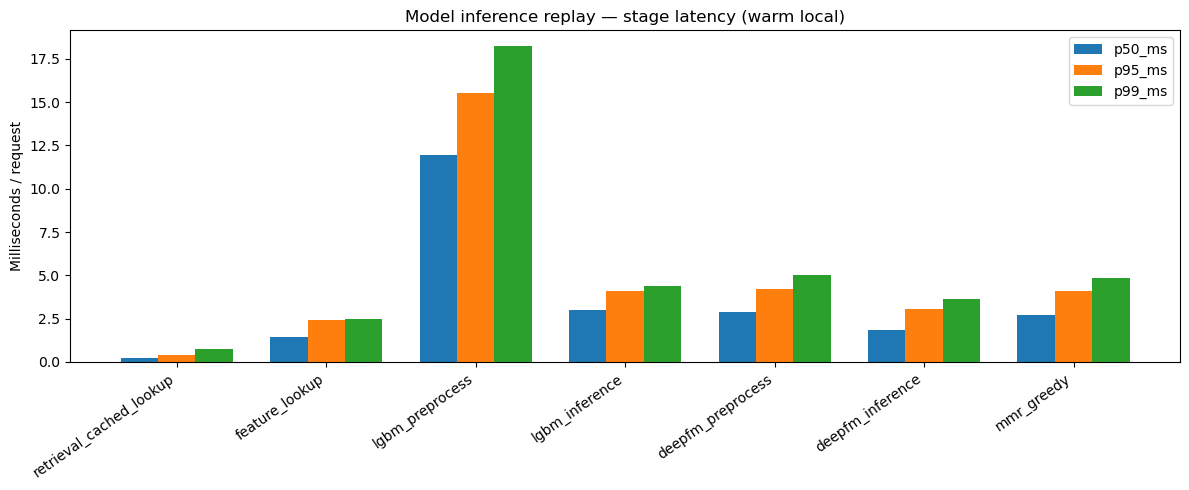

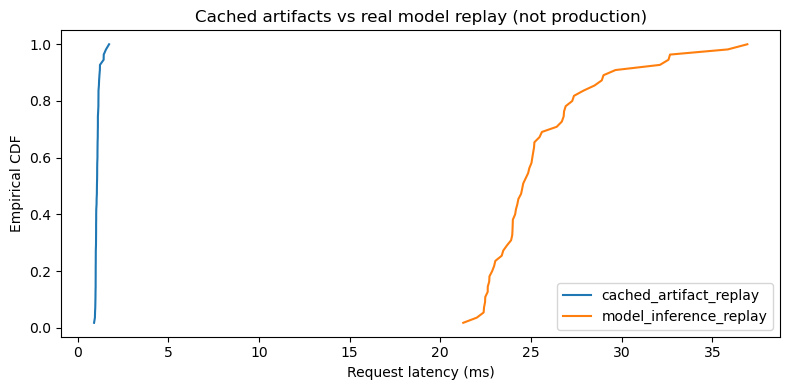

Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook14_replay_report.json


,mode,n_requests,p50_ms,p95_ms,p99_ms,mean_ms,sequential_qps,candidate_count,user_coverage
0,cached_artifact_replay,55,1.0685,1.4372,1.6436,1.0983,910.4694,500,1.0
1,model_inference_replay,55,24.5695,32.6064,36.3473,25.5766,39.0983,500,1.0


In [10]:
STAGES.to_csv(REPORT/'notebook14_stage_samples.csv',index=False)
REQUESTS.to_csv(REPORT/'notebook14_request_samples.csv',index=False)
AUDIT.to_csv(REPORT/'notebook14_pipeline_audit.csv',index=False)
stats.to_csv(REPORT/'notebook14_stage_latency.csv',index=False)
REQSTATS.to_csv(REPORT/'notebook14_request_latency_qps.csv',index=False)
fig,ax=plt.subplots(figsize=(12,5))
subset=stats[stats['mode']=='model_inference_replay'];x=np.arange(len(subset));w=.25
for i,key in enumerate(('p50_ms','p95_ms','p99_ms')):ax.bar(x+(i-1)*w,subset[key],width=w,label=key)
ax.set_xticks(x);ax.set_xticklabels(subset.stage,rotation=35,ha='right');ax.set_ylabel('Milliseconds / request');ax.set_title('Model inference replay — stage latency (warm local)');ax.legend();fig.tight_layout();fig.savefig(PLOTS/'notebook14_stage_latency.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for mode,sub in REQUESTS.groupby('mode'):
    v=np.sort(sub.latency_ms.to_numpy());ax.plot(v,np.arange(1,len(v)+1)/len(v),label=mode)
ax.set_xlabel('Request latency (ms)');ax.set_ylabel('Empirical CDF');ax.set_title('Cached artifacts vs real model replay (not production)');ax.legend();fig.tight_layout();fig.savefig(PLOTS/'notebook14_request_latency_cdf.png',dpi=150);plt.show()

def safe(v):
    if isinstance(v,dict):return {str(k):safe(x) for k,x in v.items()}
    if isinstance(v,(list,tuple)):return [safe(x) for x in v]
    if isinstance(v,(np.integer,)):return int(v)
    if isinstance(v,(np.floating,)):return float(v)
    if isinstance(v,np.bool_):return bool(v)
    return v
report={'notebook':'14_offline_replay_latency_benchmark','seed':SEED,'split':SPLIT,'device':str(DEVICE),
 'environment':{'python':sys.version.split()[0],'platform':platform.platform(),'torch':torch.__version__,'lightgbm':lgb.__version__},
 'replay':{'requests_total':int(len(selected)),'warmup_requests':int(len(warmup)),'timed_requests':int(len(requests)),
   'selected_user_ids':[int(x) for x in selected],'mmr_lambda_frozen':MMR_LAMBDA,'mmr_pool':MMR_POOL,'mmr_depth':MMR_DEPTH,
   'artifact_load_seconds_excluded':load_seconds,'retrieval_source':'precomputed Notebook08 RRF top500','feature_source':'precomputed Notebook09 features'},
 'request_latency_qps':REQSTATS.to_dict('records'),'stage_latency':stats.to_dict('records'),
 'audit':{'candidate_count_min':int(AUDIT.candidate_count.min()),'candidate_count_max':int(AUDIT.candidate_count.max()),
   'unique_candidates_min':int(AUDIT.unique_candidates.min()),'lgbm_max_abs_error':float(AUDIT.lgbm_max_abs_error.max()),
   'deepfm_max_abs_error':float(AUDIT.deepfm_max_abs_error.max()),'mmr_exact_top20_rate':float(AUDIT.mmr_exact_top20.mean()),
   'mmr_exact_top500_rate':float(AUDIT.mmr_exact_top500.mean()),'user_coverage':request_coverage(requests)},
 'exports':['notebook14_stage_samples.csv','notebook14_request_samples.csv','notebook14_pipeline_audit.csv','notebook14_stage_latency.csv','notebook14_request_latency_qps.csv','notebook14_plots/notebook14_stage_latency.png','notebook14_plots/notebook14_request_latency_cdf.png'],
 'limitations':['Cached replay only measures in-memory artifact lookup, not retrieval or inference',
 'Real-model replay uses cached Notebook08 retrieval candidates and Notebook09 feature values; no raw-event retrieval/feature generation',
 'Single-process sequential warm benchmark, no network/concurrency/serialization/cold start','GPU synchronization included; hardware-specific results',
 'Test used only for frozen implementation audit and timing, not hyperparameter selection','No production latency or online CTR/CVR claim']}
report_path=REPORT/'notebook14_replay_report.json';report_path.write_text(json.dumps(safe(report),indent=2,ensure_ascii=False),encoding='utf-8')
print('Saved:',report_path);display(REQSTATS.round(4))


## 10. Completion checklist and interpretation

- [ ] All required Notebook 08–13 artifacts found; every user has 500 unique candidates.
- [ ] Model score parity with Notebook 10/11 confirmed; frozen MMR Top-20 matches Notebook 13.
- [ ] Both cached lookup and **real** LightGBM/PyTorch/MMR timings reported separately.
- [ ] Stage and request P50/P95/P99, sequential QPS, candidate count, coverage and audits exported.
- [ ] Notebook 14 JSON and PNG plots saved.

**Next:** Notebook 15 FastAPI. To estimate real serving latency, implement request-time retrieval and feature lookups, serialization, network overhead, concurrency and cold-start benchmarking. Never label this replay as production QPS.